# 04 · Baseline vs. supervised models: does sentiment add anything over price? (H3)

**Supervised learning only.** Every model here is a supervised classifier fitted to the labelled
target `price_direction` (1 = gold rises from (t+1):00 to (t+2):00). No clustering, dimensionality
reduction or other unsupervised steps are used anywhere in the pipeline.

| # | Model | Inputs |
|---|---|---|
| 1 | Majority class (`DummyClassifier`) | none |
| 2 | Logistic regression, **price-only** | last return (+ missing flag), hour of day |
| 3 | Logistic regression, **price + sentiment** | (2) + sentiment, rolling means/stds, lags, volume, engagement, weekday |
| 4 | Decision tree, depth 3 (fixed) | same as (3) |

H3 is the comparison between (2) and (3). No hyperparameter search and no boosting: defaults,
fixed in advance.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from processing.features import PRICE_FEATURES, SENTIMENT_FEATURES

features = pd.read_parquet("data/clean/features.parquet")
data = features[features["target_valid"]].copy()
data["y"] = data["price_direction"].astype(int)
ALL_FEATURES = PRICE_FEATURES + SENTIMENT_FEATURES
assert data[ALL_FEATURES].notna().all().all(), "model inputs must have no NaNs"

## Time-ordered split
Train on everything before **Sept 28 00:00 UTC** and test on Sept 28 → Oct 5. No shuffling.
The test week never informs training, including the feature scaling (the scaler is fitted inside
each pipeline, on training rows only).

In [2]:
SPLIT = pd.Timestamp("2026-09-28 00:00", tz="UTC")
train, test = data[data.index < SPLIT], data[data.index >= SPLIT]
assert train.index.max() < test.index.min()          # no look-ahead across the split
assert (len(train), len(test)) == (307, 124)
for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part)} rows, {part.index.min():%b %d %H:%M} → {part.index.max():%b %d %H:%M}, "
          f"up = {part['y'].mean():.1%}")

train: 307 rows, Sep 08 03:00 → Sep 27 23:00, up = 46.9%
test: 124 rows, Sep 28 00:00 → Oct 05 13:00, up = 50.8%


In [3]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def make_models():
    return {
        "1 majority class": (DummyClassifier(strategy="most_frequent"), []),
        "2 logistic, price-only": (make_pipeline(StandardScaler(), LogisticRegression()), PRICE_FEATURES),
        "3 logistic, price + sentiment": (make_pipeline(StandardScaler(), LogisticRegression()), ALL_FEATURES),
        "4 decision tree (depth 3), price + sentiment": (DecisionTreeClassifier(max_depth=3, random_state=0), ALL_FEATURES),
    }

def fit_all(train, test):
    """Fits the four supervised models on train, scores them on test."""
    models, rows, preds = make_models(), [], {}
    for name, (model, cols) in models.items():
        X_tr = train[cols] if cols else np.zeros((len(train), 1))
        X_te = test[cols] if cols else np.zeros((len(test), 1))
        model.fit(X_tr, train["y"])
        preds[name] = model.predict(X_te)
        k = int((preds[name] == test["y"]).sum())
        lo, hi = wilson(k, len(test))
        rows.append({"model": name, "n_features": len(cols), "n_train": len(train), "n_test": len(test),
                     "train_acc": accuracy_score(train["y"], model.predict(X_tr)),
                     "test_acc": k / len(test), "ci95_low": lo, "ci95_high": hi,
                     "pred_up_share": preds[name].mean()})
    return pd.DataFrame(rows), preds, models

results, preds, MODELS = fit_all(train, test)
results.round(3)

,model,n_features,n_train,n_test,train_acc,test_acc,ci95_low,ci95_high,pred_up_share
0,1 majority class,0,307,124,0.531,0.492,0.406,0.579,0.000
1,"2 logistic, price-only",4,307,124,0.550,0.484,0.398,0.571,0.315
2,"3 logistic, price + sentiment",19,307,124,0.622,0.565,0.477,0.649,0.508
3,"4 decision tree (depth 3), price + sentiment",19,307,124,0.681,0.516,0.429,0.602,0.492


## Confusion matrices (test set, Sept 28 → Oct 5)

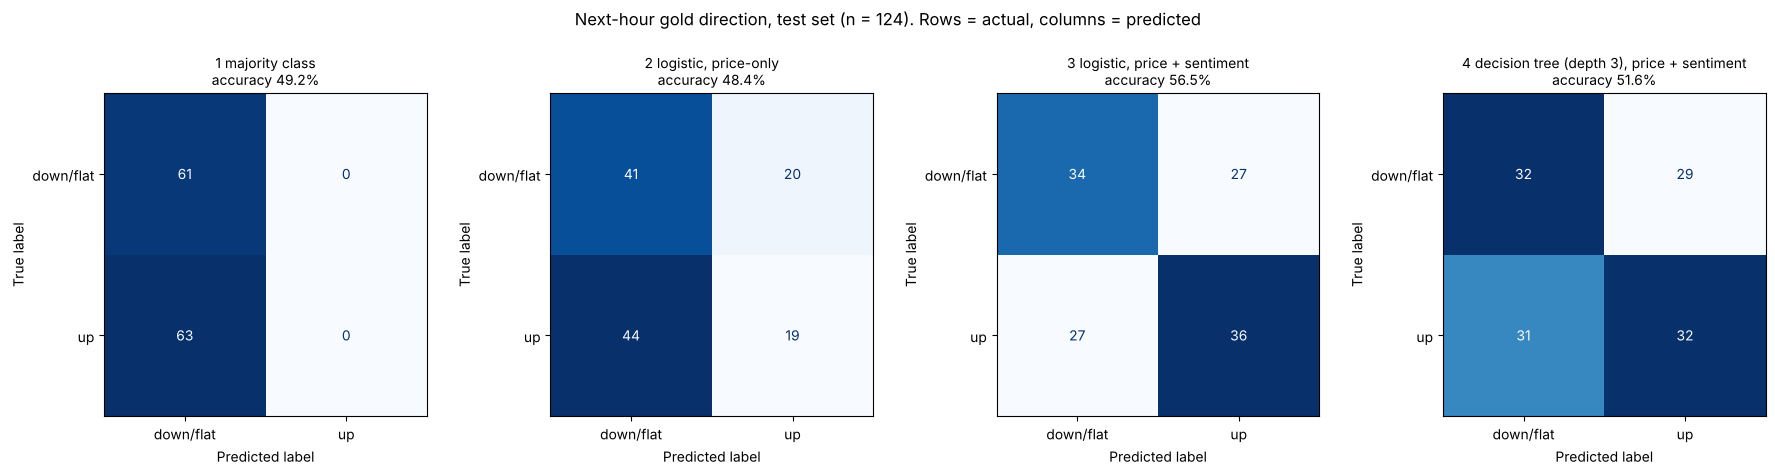

In [4]:
labels_txt = ["down/flat", "up"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(test["y"], p, labels=[0, 1]), display_labels=labels_txt
                           ).plot(ax=ax, colorbar=False, cmap="Blues")
    acc = results.set_index("model").loc[name, "test_acc"]
    ax.set_title(f"{name}\naccuracy {acc:.1%}", fontsize=10)
fig.suptitle("Next-hour gold direction, test set (n = 124). Rows = actual, columns = predicted", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES / "model_cm_all.png", dpi=150, bbox_inches="tight")

for i, (name, p) in enumerate(preds.items(), start=1):
    f1, a1 = plt.subplots(figsize=(4.2, 3.8))
    ConfusionMatrixDisplay(confusion_matrix(test["y"], p, labels=[0, 1]), display_labels=labels_txt
                           ).plot(ax=a1, colorbar=False, cmap="Blues")
    a1.set_title(f"{name}\naccuracy {(p == test['y']).mean():.1%}", fontsize=9.5)
    f1.tight_layout()
    f1.savefig(FIGURES / f"model_cm_{i}.png", dpi=150, bbox_inches="tight")
    plt.close(f1)

## H3: does adding sentiment beat price-only?
Exact McNemar test on the test set: among hours where exactly one of models 2 and 3 is right, is
either one right more often than chance?

In [5]:
y = test["y"].to_numpy()
p2, p3 = preds["2 logistic, price-only"], preds["3 logistic, price + sentiment"]
only2, only3 = int(((p2 == y) & (p3 != y)).sum()), int(((p3 == y) & (p2 != y)).sum())
mcnemar_p = binomtest(only3, only2 + only3, 0.5).pvalue if only2 + only3 else 1.0
print(f"only price-only right: {only2}   only price+sentiment right: {only3}   exact McNemar p = {mcnemar_p:.3f}")
p1 = preds["1 majority class"]
b1, b3 = int(((p1 == y) & (p3 != y)).sum()), int(((p3 == y) & (p1 != y)).sum())
print(f"model 3 vs majority class: only majority right {b1}, only model 3 right {b3}, "
      f"exact McNemar p = {binomtest(b3, b1 + b3, 0.5).pvalue:.3f}")

base = results.loc[0, "test_acc"]
for _, r in results.iterrows():
    print(f"{r['model']:<46} test {r['test_acc']:.1%}  [95% CI {r['ci95_low']:.1%} – {r['ci95_high']:.1%}]  "
          f"train {r['train_acc']:.1%}  Δ vs majority {100 * (r['test_acc'] - base):+.1f} pts")

only price-only right: 19   only price+sentiment right: 29   exact McNemar p = 0.193
model 3 vs majority class: only majority right 27, only model 3 right 36, exact McNemar p = 0.314
1 majority class                               test 49.2%  [95% CI 40.6% – 57.9%]  train 53.1%  Δ vs majority +0.0 pts
2 logistic, price-only                         test 48.4%  [95% CI 39.8% – 57.1%]  train 55.0%  Δ vs majority -0.8 pts
3 logistic, price + sentiment                  test 56.5%  [95% CI 47.7% – 64.9%]  train 62.2%  Δ vs majority +7.3 pts
4 decision tree (depth 3), price + sentiment   test 51.6%  [95% CI 42.9% – 60.2%]  train 68.1%  Δ vs majority +2.4 pts


### What the price + sentiment logistic regression leaned on (standardised coefficients)

In [6]:
lr3 = MODELS["3 logistic, price + sentiment"][0]
coef = pd.Series(lr3[-1].coef_[0], index=ALL_FEATURES).sort_values(key=abs, ascending=False)
coef.round(3).to_frame("coef (per 1 sd)")

,coef (per 1 sd)
sent_roll_mean_6h,0.434
sent_roll_std_6h_filled,-0.404
engagement_missing,0.361
log_post_count_lag2,0.306
last_return_filled,-0.305
mean_sentiment_lag2,0.250
sent_roll_std_3h_filled,0.237
log_post_count,0.216
hour_cos,-0.159
log_engagement,-0.156


In [7]:
print(export_text(MODELS["4 decision tree (depth 3), price + sentiment"][0], feature_names=ALL_FEATURES))

|--- sent_roll_mean_6h <= 0.23
|   |--- bullish_ratio_lag2 <= 0.61
|   |   |--- last_return_filled <= -0.00
|   |   |   |--- class: 0
|   |   |--- last_return_filled >  -0.00
|   |   |   |--- class: 0
|   |--- bullish_ratio_lag2 >  0.61
|   |   |--- log_post_count_lag2 <= 1.50
|   |   |   |--- class: 0
|   |   |--- log_post_count_lag2 >  1.50
|   |   |   |--- class: 1
|--- sent_roll_mean_6h >  0.23
|   |--- last_return_filled <= -0.00
|   |   |--- sent_roll_mean_6h <= 0.25
|   |   |   |--- class: 0
|   |   |--- sent_roll_mean_6h >  0.25
|   |   |   |--- class: 1
|   |--- last_return_filled >  -0.00
|   |   |--- sent_roll_std_6h_filled <= 0.26
|   |   |   |--- class: 1
|   |   |--- sent_roll_std_6h_filled >  0.26
|   |   |   |--- class: 0



## How to read this honestly
* The bar to beat is the majority class learned from training: always predicting "down/flat". Over
  all 431 rows that would score 52%, but the **test week happened to be 50.8% up**, so on the test set
  it scores **49.2%**. The baseline is fitted on training data only, as it must be.
* With **124 test hours**, a 95% interval on accuracy is roughly **±9 points** (the Wilson intervals
  above). An accuracy of 55% against a 52% baseline is **not** evidence of skill.
* H3 is supported only if model 3 beats model 2 by more than noise (McNemar p < 0.05) *and* beats
  the baseline. A negative or inconclusive result is a valid finding and is reported as such.
* Limitations: four weeks of data, one test week, GC=F futures as a proxy for spot (pitfall #7),
  VADER scores on short Reddit titles (about a third score exactly 0), and the test week (Sept 28 →
  Oct 5) may not look like the training weeks.

## Variant: without r/Silverbugs

Hand-labelling showed that r/Silverbugs is mostly **silver collecting** with no view on the gold
price. This variant rebuilds the hourly table from the **same stored posts** minus r/Silverbugs,
keeping r/Gold and r/investing:

    python -m processing.bucket --end 2026-10-05T15:00 --exclude-subreddits Silverbugs \
        --output data/clean/hourly_merged_no_silverbugs.parquet
    python -m processing.features --input data/clean/hourly_merged_no_silverbugs.parquet \
        --output data/clean/features_no_silverbugs.parquet

Nothing was re-collected or re-scored. Silverbugs is dropped **before** de-duplication, so a story
cross-posted to both communities keeps its r/Gold copy.

The target depends only on price, so **both variants are tested on exactly the same 124 hours**.
That allows a paired comparison. Models 1 and 2 use no sentiment, so they must score identically.

In [8]:
features_v = pd.read_parquet("data/clean/features_no_silverbugs.parquet")
data_v = features_v[features_v["target_valid"]].copy()
data_v["y"] = data_v["price_direction"].astype(int)
assert data_v.index.equals(data.index) and (data_v["y"] == data["y"]).all()
assert data_v[ALL_FEATURES].notna().all().all()
train_v, test_v = data_v[data_v.index < SPLIT], data_v[data_v.index >= SPLIT]
assert train_v.index.max() < test_v.index.min() and (len(train_v), len(test_v)) == (307, 124)

for label, f in [("all communities", features), ("no Silverbugs", features_v)]:
    v = f[f["target_valid"]]
    print(f"{label:<16} posts/hour {f['post_count'].mean():.2f}   hours with no posts "
          f"{(~f['had_posts']).mean():.0%}   target-valid hours with posts {v['had_posts'].mean():.0%}")

results_v, preds_v, MODELS_V = fit_all(train_v, test_v)
for name in ["1 majority class", "2 logistic, price-only"]:
    assert (preds_v[name] == preds[name]).all(), f"{name} should not depend on sentiment"

combined = pd.concat([results.assign(dataset="all communities"),
                      results_v.assign(dataset="no Silverbugs")], ignore_index=True)
combined = combined[["dataset"] + [c for c in combined.columns if c != "dataset"]]
Path("reports").mkdir(exist_ok=True)   # reports/model_results.csv is written once, below
combined.pivot(index="model", columns="dataset", values="test_acc").map("{:.1%}".format)

all communities  posts/hour 3.64   hours with no posts 6%   target-valid hours with posts 94%
no Silverbugs    posts/hour 1.73   hours with no posts 22%   target-valid hours with posts 78%


dataset,all communities,no Silverbugs
model,,
1 majority class,49.2%,49.2%
"2 logistic, price-only",48.4%,48.4%
"3 logistic, price + sentiment",56.5%,50.0%
"4 decision tree (depth 3), price + sentiment",51.6%,62.1%


In [9]:
def mcnemar(a, b, y):
    """Exact McNemar on paired predictions: (only a right, only b right, p)."""
    only_a, only_b = int(((a == y) & (b != y)).sum()), int(((b == y) & (a != y)).sum())
    return only_a, only_b, (binomtest(only_b, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0)

m3, m3v = preds["3 logistic, price + sentiment"], preds_v["3 logistic, price + sentiment"]
m4, m4v = preds["4 decision tree (depth 3), price + sentiment"], preds_v["4 decision tree (depth 3), price + sentiment"]
p2_, p1_ = preds["2 logistic, price-only"], preds["1 majority class"]
for label, a, b in [("model 3: all communities vs no Silverbugs", m3, m3v),
                    ("model 4: all communities vs no Silverbugs", m4, m4v),
                    ("no Silverbugs: price-only vs model 3", p2_, m3v),
                    ("no Silverbugs: majority vs model 3", p1_, m3v),
                    ("no Silverbugs: price-only vs model 4", p2_, m4v),
                    ("no Silverbugs: majority vs model 4", p1_, m4v)]:
    oa, ob, p = mcnemar(a, b, y)
    print(f"{label:<44} only first right {oa:>3}   only second right {ob:>3}   exact McNemar p = {p:.3f}")
# Four sentiment models were tried against price-only (2 models x 2 datasets): more tries mean
# more chances of a lucky win. Bonferroni: require p < 0.05 / 4.
print("\nmultiple-comparison threshold (Bonferroni, 4 sentiment models vs price-only): p < 0.0125")
print()
for _, r in results_v.iterrows():
    print(f"{r['model']:<46} test {r['test_acc']:.1%}  [95% CI {r['ci95_low']:.1%} – {r['ci95_high']:.1%}]  "
          f"train {r['train_acc']:.1%}")

model 3: all communities vs no Silverbugs    only first right  29   only second right  21   exact McNemar p = 0.322
model 4: all communities vs no Silverbugs    only first right  28   only second right  41   exact McNemar p = 0.148
no Silverbugs: price-only vs model 3         only first right  19   only second right  21   exact McNemar p = 0.875
no Silverbugs: majority vs model 3           only first right  16   only second right  17   exact McNemar p = 1.000
no Silverbugs: price-only vs model 4         only first right  24   only second right  41   exact McNemar p = 0.046
no Silverbugs: majority vs model 4           only first right  26   only second right  42   exact McNemar p = 0.068

multiple-comparison threshold (Bonferroni, 4 sentiment models vs price-only): p < 0.0125

1 majority class                               test 49.2%  [95% CI 40.6% – 57.9%]  train 53.1%
2 logistic, price-only                         test 48.4%  [95% CI 39.8% – 57.1%]  train 55.0%
3 logistic, price + sen

,all communities,no Silverbugs
log_post_count,0.216,-0.468
engagement_missing,0.361,-0.413
log_post_count_lag1,-0.087,-0.302
sent_roll_mean_6h,0.434,0.271
last_return_filled,-0.305,-0.224
mean_sentiment_lag2,0.250,0.221
mean_sentiment,-0.063,-0.189
log_engagement,-0.156,-0.182
hour_sin,0.086,-0.169
return_missing,-0.143,-0.162


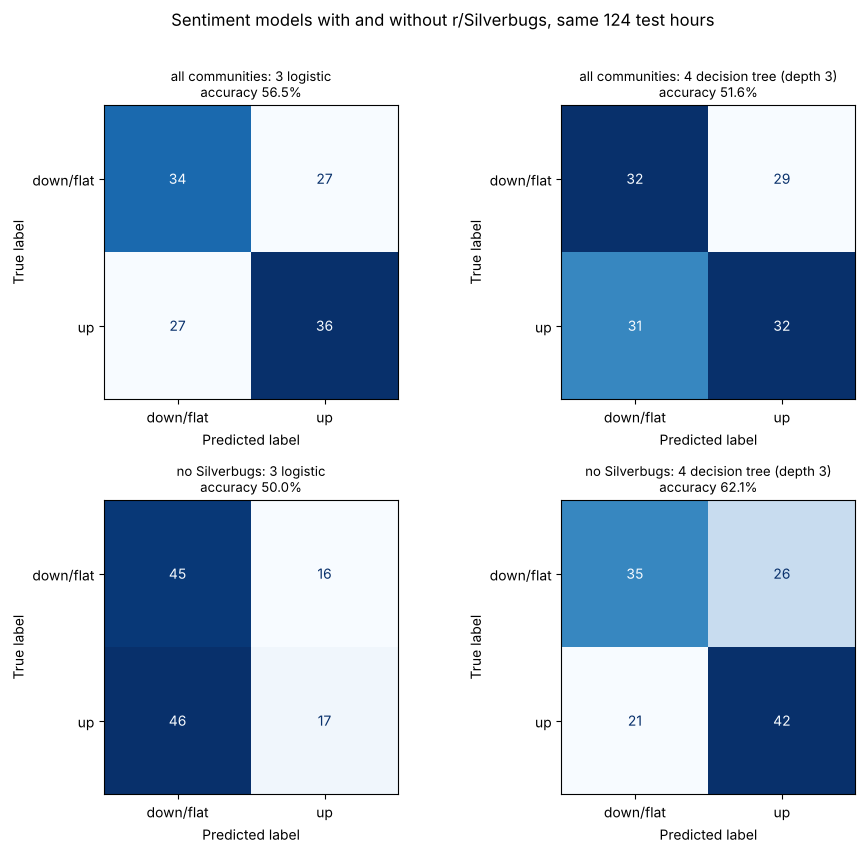

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.4))
for row, (label, p) in enumerate([("all communities", preds), ("no Silverbugs", preds_v)]):
    for col, name in enumerate(["3 logistic, price + sentiment", "4 decision tree (depth 3), price + sentiment"]):
        ax = axes[row, col]
        ConfusionMatrixDisplay(confusion_matrix(y, p[name], labels=[0, 1]), display_labels=labels_txt
                               ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{label}: {name.split(',')[0]}\naccuracy {(p[name] == y).mean():.1%}", fontsize=9.5)
fig.suptitle("Sentiment models with and without r/Silverbugs, same 124 test hours", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES / "model_cm_all_vs_no_silverbugs.png", dpi=150, bbox_inches="tight")

lr3v = MODELS_V["3 logistic, price + sentiment"][0]
pd.DataFrame({"all communities": pd.Series(lr3[-1].coef_[0], index=ALL_FEATURES),
              "no Silverbugs": pd.Series(lr3v[-1].coef_[0], index=ALL_FEATURES)}
             ).sort_values("no Silverbugs", key=abs, ascending=False).round(3)

### Sensitivity check: is the variant tree's score stable?
**This is not tuning.** The reported model stays fixed at depth 3 and the Sept 28 split. The check
only asks whether the score survives small, arbitrary changes. A real signal should; a lucky one
won't.

In [11]:
rows_s = []
for depth in [2, 3, 4]:
    for split in ["2026-09-26", "2026-09-28", "2026-09-30"]:
        s = pd.Timestamp(split, tz="UTC")
        for label, d in [("all communities", data), ("no Silverbugs", data_v)]:
            tr, te = d[d.index < s], d[d.index >= s]
            tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(tr[ALL_FEATURES], tr["y"])
            rows_s.append({"dataset": label, "depth": depth, "split": split, "n_test": len(te),
                           "tree_acc": (tree.predict(te[ALL_FEATURES]) == te["y"]).mean(),
                           "majority_acc": (te["y"] == tr["y"].mode()[0]).mean()})
sens = pd.DataFrame(rows_s)
sens.pivot_table(index=["dataset", "depth"], columns="split", values="tree_acc").map("{:.1%}".format)

split                 2026-09-26 2026-09-28 2026-09-30
dataset         depth                                 
all communities 2          46.5%      43.5%      55.0%
                3          54.3%      51.6%      50.0%
                4          55.9%      54.8%      51.2%
no Silverbugs   2          43.3%      42.7%      52.5%
                3          62.2%      62.1%      53.8%
                4          55.1%      55.6%      47.5%

### Reading the variant
* Dropping r/Silverbugs halves the posts (2,419 → 1,146), so far more hours have no post and
  carry a forward-filled mood. The mood clues get **more on-topic but thinner**.
* The same rule applies as above: a difference only counts if McNemar p < 0.05. Because we have now
  tried **four** sentiment models (2 models × 2 datasets) against price-only, the stricter
  Bonferroni bar is **p < 0.0125**. Trying more combinations makes a lucky win more likely.
* Watch for the logistic and tree models disagreeing. If removing Silverbugs helps one model and
  hurts the other, that points to noise, not a real signal.
* `data/clean/features.parquet` (all communities) remains the main feature table for Track C. The
  variant file exists only for this comparison.

## Second scorer: FinBERT (with and without r/Silverbugs)

Same posts, same de-duplication, same features, same split. Only the per-post score changes:
VADER's compound is replaced by FinBERT's P(positive) − P(negative), and the bullish/bearish ratios come
from FinBERT's most likely class (see `02_features.ipynb` §4 and `sentiment/finbert.py`):

    python -m sentiment.finbert
    python -m processing.bucket --end 2026-10-05T15:00 --sentiment-file data/clean/post_sentiment_finbert.parquet \
        --output data/clean/hourly_merged_finbert.parquet
    python -m processing.features --input data/clean/hourly_merged_finbert.parquet \
        --output data/clean/features_finbert.parquet
    # + the same two steps with --exclude-subreddits Silverbugs -> *_finbert_no_silverbugs.parquet

The test hours are identical, so every comparison is paired. With **8 sentiment models** now tried
against price-only (2 models × 2 datasets × 2 scorers), the Bonferroni bar is **p < 0.05 / 8 = 0.00625**.

In [12]:
datasets = {"VADER, all communities": (data, results, preds),
            "VADER, no Silverbugs": (data_v, results_v, preds_v)}
for label, path in [("FinBERT, all communities", "data/clean/features_finbert.parquet"),
                    ("FinBERT, no Silverbugs", "data/clean/features_finbert_no_silverbugs.parquet")]:
    f = pd.read_parquet(path)
    d = f[f["target_valid"]].copy()
    d["y"] = d["price_direction"].astype(int)
    assert d.index.equals(data.index) and (d["y"] == data["y"]).all()
    assert d[ALL_FEATURES].notna().all().all()
    tr, te = d[d.index < SPLIT], d[d.index >= SPLIT]
    assert (len(tr), len(te)) == (307, 124)
    r, p, _ = fit_all(tr, te)
    for name in ["1 majority class", "2 logistic, price-only"]:
        assert (p[name] == preds[name]).all(), f"{name} should not depend on sentiment"
    datasets[label] = (d, r, p)

combined = pd.concat([r.assign(dataset=k) for k, (_, r, _) in datasets.items()], ignore_index=True)
combined = combined[["dataset"] + [c for c in combined.columns if c != "dataset"]]
# Replace only this notebook's datasets: the file also holds rows from notebooks 05-07
# (economy mood, daily, Bloomberg), and the daily/Bloomberg ones need data not in the repository.
RESULTS = Path("reports/model_results.csv")
others = pd.read_csv(RESULTS) if RESULTS.exists() else combined.iloc[:0]
others = others[~others["dataset"].isin(combined["dataset"])]
pd.concat([combined.round(4), others], ignore_index=True).to_csv(RESULTS, index=False)
combined.pivot(index="model", columns="dataset", values="test_acc")[list(datasets)].map("{:.1%}".format)

dataset,"VADER, all communities","VADER, no Silverbugs","FinBERT, all communities","FinBERT, no Silverbugs"
model,,,,
1 majority class,49.2%,49.2%,49.2%,49.2%
"2 logistic, price-only",48.4%,48.4%,48.4%,48.4%
"3 logistic, price + sentiment",56.5%,50.0%,52.4%,48.4%
"4 decision tree (depth 3), price + sentiment",51.6%,62.1%,54.8%,47.6%


In [13]:
BONFERRONI = 0.05 / 8
M3, M4 = "3 logistic, price + sentiment", "4 decision tree (depth 3), price + sentiment"
rows_t = []
for label, (_, _, p) in datasets.items():
    for m in [M3, M4]:
        oa, ob, pv = mcnemar(p2_, p[m], y)
        ma, mb, pm = mcnemar(p1_, p[m], y)
        rows_t.append({"dataset": label, "model": m.split(",")[0], "test_acc": (p[m] == y).mean(),
                       "vs price-only: only price right": oa, "only sentiment right": ob, "p": pv,
                       "vs majority p": pm, f"beats price-only at p<{BONFERRONI:.4f}": pv < BONFERRONI and ob > oa})
display(pd.DataFrame(rows_t).round(3))
for m in [M3, M4]:
    oa, ob, pv = mcnemar(datasets["VADER, all communities"][2][m], datasets["FinBERT, all communities"][2][m], y)
    print(f"{m.split(',')[0]}: VADER vs FinBERT (all communities)  only VADER right {oa}  only FinBERT right {ob}  p = {pv:.3f}")

,dataset,model,test_acc,vs price-only: only price right,only sentiment right,p,vs majority p,beats price-only at p<0.0063
0,"VADER, all communities",3 logistic,0.565,19,29,0.193,0.314,False
1,"VADER, all communities",4 decision tree (depth 3),0.516,21,25,0.659,0.798,False
2,"VADER, no Silverbugs",3 logistic,0.500,19,21,0.875,1.000,False
3,"VADER, no Silverbugs",4 decision tree (depth 3),0.621,24,41,0.046,0.068,False
4,"FinBERT, all communities",3 logistic,0.524,24,29,0.583,0.712,False
5,"FinBERT, all communities",4 decision tree (depth 3),0.548,31,39,0.403,0.510,False
6,"FinBERT, no Silverbugs",3 logistic,0.484,20,20,1.000,1.000,False
7,"FinBERT, no Silverbugs",4 decision tree (depth 3),0.476,32,31,1.000,0.913,False


3 logistic: VADER vs FinBERT (all communities)  only VADER right 20  only FinBERT right 15  p = 0.500
4 decision tree (depth 3): VADER vs FinBERT (all communities)  only VADER right 31  only FinBERT right 35  p = 0.712


In [14]:
rows_s = []
for depth in [2, 3, 4]:
    for split in ["2026-09-26", "2026-09-28", "2026-09-30"]:
        s = pd.Timestamp(split, tz="UTC")
        for label, (d, _, _) in datasets.items():
            tr, te = d[d.index < s], d[d.index >= s]
            tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(tr[ALL_FEATURES], tr["y"])
            rows_s.append({"dataset": label, "depth": depth, "split": split,
                           "tree_acc": (tree.predict(te[ALL_FEATURES]) == te["y"]).mean()})
print("Tree sensitivity across all four datasets (not tuning; the reported model stays depth 3, Sept 28):")
pd.DataFrame(rows_s).pivot_table(index=["dataset", "depth"], columns="split", values="tree_acc").map("{:.1%}".format)

Tree sensitivity across all four datasets (not tuning; the reported model stays depth 3, Sept 28):


split                          2026-09-26 2026-09-28 2026-09-30
dataset                  depth                                 
FinBERT, all communities 2          47.2%      51.6%      42.5%
                         3          42.5%      54.8%      37.5%
                         4          43.3%      50.8%      33.8%
FinBERT, no Silverbugs   2          44.1%      44.4%      38.8%
                         3          47.2%      47.6%      48.8%
                         4          47.2%      47.6%      40.0%
VADER, all communities   2          46.5%      43.5%      55.0%
                         3          54.3%      51.6%      50.0%
                         4          55.9%      54.8%      51.2%
VADER, no Silverbugs     2          43.3%      42.7%      52.5%
                         3          62.2%      62.1%      53.8%
                         4          55.1%      55.6%      47.5%

### Reading the FinBERT comparison
* Which scorer to recommend was decided **before** this table, on agreement with the human labels
  (`02_features.ipynb` §4), not on which one happens to score higher here.
* FinBERT calls most posts neutral, so its hourly features are much flatter (many hours with a
  bullish/bearish ratio of 0). A better-measured mood can still carry no next-hour price signal.
* The same rules apply: a difference only counts at **p < 0.00625**, and only if it also survives the
  sensitivity grid above. Logistic and tree models moving in opposite directions point to noise.